<a href="https://colab.research.google.com/github/vacchiano/machine-learning-practice/blob/master/linear_regression_palmer_penguins.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Part 1 - load the data

url="https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

df = pd.read_csv(url)

#keeping these 2 columns, removing rows with missing values in either
# df = df[["flipper_length_mm", "body_mass_g"]].dropna()
df = df[["bill_length_mm", "body_mass_g"]].dropna()

print(df.shape)
print(df.head())

(342, 2)
   bill_length_mm  body_mass_g
0            39.1       3750.0
1            39.5       3800.0
2            40.3       3250.0
4            36.7       3450.0
5            39.3       3650.0


### Demonstrating Single vs. Double Brackets
Let's run a quick comparison to see how the returned types and visual outputs differ.

In [31]:
# quick Pandas interlude

# 1. Single brackets returns a Series
# single_bracket = df['flipper_length_mm']
# print("Single bracket type:", type(single_bracket))

# # 2. Double brackets with one column returns a DataFrame
# double_bracket_one = df[['flipper_length_mm']]
# print("Double bracket (one col) type:", type(double_bracket_one))

# # 3. Double brackets with multiple columns returns a DataFrame
# double_bracket_two = df[['flipper_length_mm', 'body_mass_g']]
# print("Double bracket (two cols) type:", type(double_bracket_two))

In [32]:
# Let's check the 'shape' (dimensions) of both objects
print("Series shape (1D):", single_bracket.shape)
print("DataFrame shape (2D):", double_bracket_one.shape)
print("DataFrame shape (3D):", double_bracket_two.shape)

Series shape (1D): (342,)
DataFrame shape (2D): (342, 1)
DataFrame shape (3D): (342, 2)


Weight:  87.4152770528755
Bias:  362.30672165392207


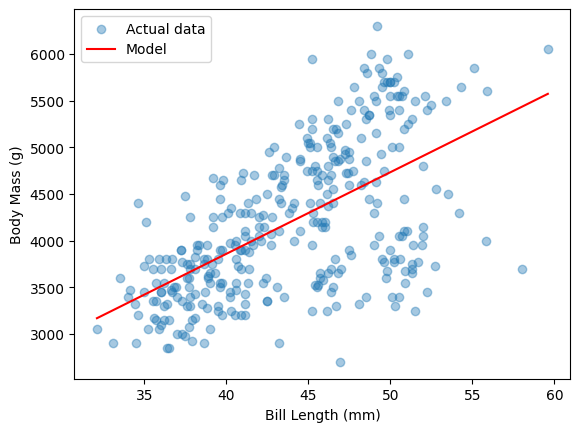

In [33]:
# Part 2 - Train & Visualize

# using numpy just for practice - sklearn expects a 2D shape
# X = df[["flipper_length_mm"]].to_numpy()
X = df[["bill_length_mm"]].to_numpy()
#sklearn takes 1D shape for y
y = df["body_mass_g"].to_numpy()

model = LinearRegression()
model.fit(X, y)

y_hat = model.predict(X)

print("Weight: ", model.coef_[0])
print("Bias: ", model.intercept_)

plt.scatter(X[:, 0], y, alpha=0.4, label="Actual data")

x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
plt.plot(x_line[:, 0], model.predict(x_line), color="red", label="Model")

# plt.xlabel("Flipper Length (mm)")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Body Mass (g)")
plt.legend()
plt.show()

In [40]:
# Part 3 - calc the cost

mse = np.mean((y_hat - y)**2)
rmse = np.sqrt(mse)

print("MSE: ", mse)
print("RMSE: ", rmse)

print(model.predict([[200]]))

# comparing different parameters (X)
print("Flipper Length MSE (mean squared error) versus Bill length MSE")
print("-> flipper MSE: 154546.186")
print("-> bill MSE: 414,148.028")

MSE:  414148.0280772337
RMSE:  643.543338149991
[17845.36213223]
Flipper Length MSE (means squared error) versus Bill length MSE
-> flipper MSE: 154546.186
-> bill MSE: 414,148.028
